# 🏠 House Price Prediction Using Machine Learning

## 1. Project Overview

**Objective:** Estimate residential property prices from listing features.

**Workflow:** Data loading → data quality checks → cleaning and price conversion → EDA → preprocessing → model training → evaluation → sample prediction.

**Algorithms:** Linear Regression (baseline) and Random Forest Regressor.

**Evaluation metrics:** MAE, RMSE, and R².

> This notebook is a cleaned, top-to-bottom version of the original workflow. Run the cells in order. Keep `house_prices.csv` in the same folder as this notebook, or update the path in the data-loading cell.

## 2. Import Libraries

In [1]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)

## 3. Load and Inspect the Dataset

In [2]:
# Keep house_prices.csv in the same folder as this notebook.
df = pd.read_csv("house_prices.csv")

print("Dataset shape:", df.shape)
display(df.head())

print("\\nDataset information:")
df.info()

print("\\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (187531, 21)


,Index,Title,Description,Amount(in rupees),Price (in rupees),location,Carpet Area,Status,Floor,Transaction,Furnishing,facing,overlooking,Society,Bathroom,Balcony,Car Parking,Ownership,Super Area,Dimensions,Plot Area
0,0,1 BHK Ready to Occupy Flat for sale in Srushti...,"Bhiwandi, Thane has an attractive 1 BHK Flat f...",42 Lac,6000.0,thane,500 sqft,Ready to Move,10 out of 11,Resale,Unfurnished,NaN,NaN,Srushti Siddhi Mangal Murti Complex,1,2,NaN,NaN,NaN,NaN,NaN
1,1,2 BHK Ready to Occupy Flat for sale in Dosti V...,One can find this stunning 2 BHK flat for sale...,98 Lac,13799.0,thane,473 sqft,Ready to Move,3 out of 22,Resale,Semi-Furnished,East,Garden/Park,Dosti Vihar,2,NaN,1 Open,Freehold,NaN,NaN,NaN
2,2,2 BHK Ready to Occupy Flat for sale in Sunrise...,Up for immediate sale is a 2 BHK apartment in ...,1.40 Cr,17500.0,thane,779 sqft,Ready to Move,10 out of 29,Resale,Unfurnished,East,Garden/Park,Sunrise by Kalpataru,2,NaN,1 Covered,Freehold,NaN,NaN,NaN
3,3,1 BHK Ready to Occupy Flat for sale Kasheli,This beautiful 1 BHK Flat is available for sal...,25 Lac,NaN,thane,530 sqft,Ready to Move,1 out of 3,Resale,Unfurnished,NaN,NaN,NaN,1,1,NaN,NaN,NaN,NaN,NaN
4,4,2 BHK Ready to Occupy Flat for sale in TenX Ha...,"This lovely 2 BHK Flat in Pokhran Road, Thane ...",1.60 Cr,18824.0,thane,635 sqft,Ready to Move,20 out of 42,Resale,Unfurnished,West,"Garden/Park, Main Road",TenX Habitat Raymond Realty,2,NaN,1 Covered,Co-operative Society,NaN,NaN,NaN


\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 187531 entries, 0 to 187530
Data columns (total 21 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Index              187531 non-null  int64  
 1   Title              187531 non-null  str    
 2   Description        184508 non-null  str    
 3   Amount(in rupees)  187531 non-null  str    
 4   Price (in rupees)  169866 non-null  float64
 5   location           187531 non-null  str    
 6   Carpet Area        106858 non-null  str    
 7   Status             186916 non-null  str    
 8   Floor              180454 non-null  str    
 9   Transaction        187448 non-null  str    
 10  Furnishing         184634 non-null  str    
 11  facing             117298 non-null  str    
 12  overlooking        106095 non-null  str    
 13  Society            77853 non-null   str    
 14  Bathroom           186703 non-null  str    
 15  Balcony            138596 non-null  str

In [3]:
# Missing values by column
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
}).sort_values("Missing_Percentage", ascending=False)

display(missing_summary)

,Missing_Count,Missing_Percentage
Plot Area,187531,100.00
Dimensions,187531,100.00
Society,109678,58.49
Super Area,107685,57.42
Car Parking,103357,55.11
overlooking,81436,43.43
Carpet Area,80673,43.02
facing,70233,37.45
Ownership,65517,34.94
Balcony,48935,26.09


## 4. Data Cleaning and Preparation

The target is `Amount(in rupees)`, which contains total property prices expressed in rupees, lakhs, or crores in the source data. We convert it to rupees.

We also standardize `Carpet Area` into a numeric `Carpet Area (sqft)` column. Unknown or unsupported area formats become missing values and are handled later by the preprocessing pipeline.

In [4]:
def convert_price(value):
    """Convert a price in rupees/lakhs/crores to rupees."""
    if pd.isna(value):
        return np.nan

    if isinstance(value, (int, float, np.number)):
        return float(value)

    text = str(value).strip().lower()
    text = text.replace(",", "").replace("₹", "").strip()

    match = re.search(r"\d+(?:\.\d+)?", text)
    if not match:
        return np.nan

    amount = float(match.group())

    if re.search(r"\b(crore|crores|cr)\b", text):
        return amount * 10_000_000
    if re.search(r"\b(lakh|lakhs|lac|lacs)\b", text):
        return amount * 100_000
    if "thousand" in text:
        return amount * 1_000

    return amount


def convert_area_to_sqft(value):
    """Convert recognized area units to square feet; unsupported values become NaN."""
    if pd.isna(value):
        return np.nan

    text = str(value).strip().lower().replace(",", "")
    match = re.search(r"(\d+(?:\.\d+)?)", text)
    if not match:
        return np.nan

    amount = float(match.group(1))
    unit_text = text[match.end():].strip().replace(".", "").replace(" ", "")

    # Recognize common spellings/abbreviations.
    if unit_text in {"", "sqft", "sqft.", "squarefeet", "squarefoot", "sqft"}:
        return amount
    if unit_text in {"sqyrd", "sqyd", "sqyard", "sqyards", "squareyards"}:
        return amount * 9
    if unit_text in {"sqm", "sqmt", "squaremeter", "squaremeters", "squaremetre", "squaremetres"}:
        return amount * 10.7639
    if unit_text in {"acre", "acres"}:
        return amount * 43_560
    if unit_text in {"cent", "cents"}:
        return amount * 435.6

    return np.nan


df_cleaned = df.copy()

# Convert the total price target to rupees.
df_cleaned["Amount(in rupees)"] = df_cleaned["Amount(in rupees)"].apply(convert_price)

# Standardize carpet area into square feet.
df_cleaned["Carpet Area (sqft)"] = df_cleaned["Carpet Area"].apply(convert_area_to_sqft)

# Remove columns that are entirely empty, if any.
df_cleaned = df_cleaned.dropna(axis=1, how="all")

print("Cleaned dataset shape:", df_cleaned.shape)
print("Missing total prices:", df_cleaned["Amount(in rupees)"].isna().sum())
print("Missing standardized carpet areas:", df_cleaned["Carpet Area (sqft)"].isna().sum())
display(df_cleaned[["Amount(in rupees)", "Price (in rupees)", "Carpet Area", "Carpet Area (sqft)"]].head(10))

Cleaned dataset shape: (187531, 20)
Missing total prices: 9684
Missing standardized carpet areas: 80680


,Amount(in rupees),Price (in rupees),Carpet Area,Carpet Area (sqft)
0,4200000.0,6000.0,500 sqft,500.0
1,9800000.0,13799.0,473 sqft,473.0
2,14000000.0,17500.0,779 sqft,779.0
3,2500000.0,NaN,530 sqft,530.0
4,16000000.0,18824.0,635 sqft,635.0
5,4500000.0,6618.0,NaN,NaN
6,1650000.0,2538.0,550 sqft,550.0
7,6000000.0,10435.0,NaN,NaN
8,6000000.0,10000.0,NaN,NaN
9,16000000.0,11150.0,900 sqft,900.0


### Target definition

The model predicts `Amount(in rupees)` (total property price). The source column `Price (in rupees)` is not included as a feature because it appears to be closely related to price per square foot and could make evaluation misleading.

In [5]:
# Rows without a usable target cannot be used for supervised training.
df_model = df_cleaned.dropna(subset=["Amount(in rupees)"]).copy()

print("Rows after removing missing target values:", len(df_model))
print("Remaining missing target values:", df_model["Amount(in rupees)"].isna().sum())
print("\\nTarget summary:")
display(df_model["Amount(in rupees)"].describe())

Rows after removing missing target values: 177847
Remaining missing target values: 0
\nTarget summary:


count    1.778470e+05
mean     1.198134e+07
std      3.943827e+07
min      1.000000e+05
25%      4.840000e+06
50%      7.800000e+06
75%      1.450000e+07
max      1.400300e+10
Name: Amount(in rupees), dtype: float64

## 5. Exploratory Data Analysis (EDA)

,Price in rupees
0.500,7.800000e+06
0.900,2.400000e+07
0.950,3.390000e+07
0.990,7.000000e+07
0.995,8.960000e+07
1.000,1.400300e+10


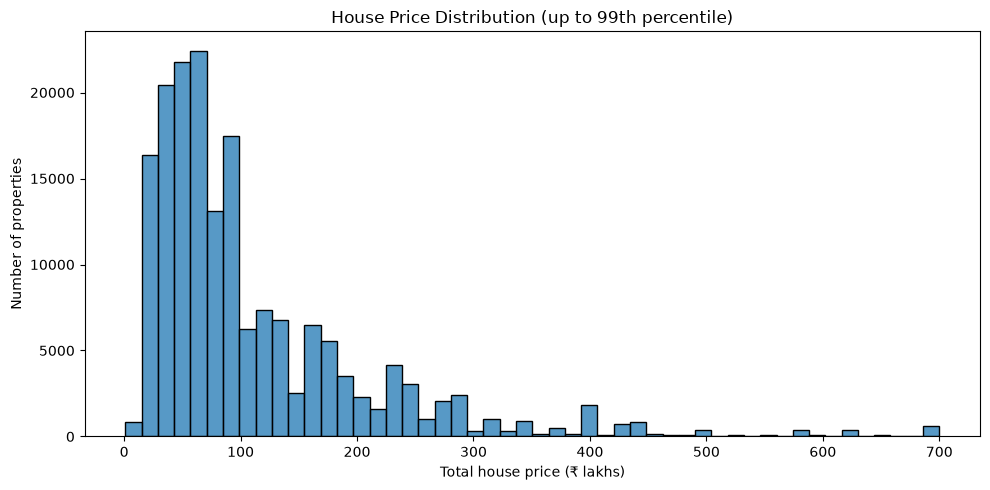

In [6]:
# Show target percentiles to understand the long right tail.
price_percentiles = df_model["Amount(in rupees)"].quantile(
    [0.50, 0.90, 0.95, 0.99, 0.995, 1.00]
)
display(price_percentiles.rename("Price in rupees").to_frame())

# Plot prices up to the 99th percentile for readability.
# This limit is for visualization only; the data is not modified here.
eda_limit = df_model["Amount(in rupees)"].quantile(0.99)
plt.figure(figsize=(10, 5))
sns.histplot(
    df_model.loc[df_model["Amount(in rupees)"] <= eda_limit, "Amount(in rupees)"] / 100_000,
    bins=50
)
plt.title("House Price Distribution (up to 99th percentile)")
plt.xlabel("Total house price (₹ lakhs)")
plt.ylabel("Number of properties")
plt.tight_layout()
plt.show()

In [7]:
# Inspect the highest-priced listings to investigate extreme values.
display(
    df_model.nlargest(10, "Amount(in rupees)")[
        [c for c in ["Title", "Amount(in rupees)", "Price (in rupees)",
                     "location", "Carpet Area (sqft)", "Status"] if c in df_model.columns]
    ]
)

,Title,Amount(in rupees),Price (in rupees),location,Carpet Area (sqft),Status
181234,3 BHK Ready to Occupy Flat for sale in Nest Ha...,1.400300e+10,6700000.0,vadodara,1252.0,Ready to Move
176536,3 BHK Ready to Occupy Flat for sale Hill Cart ...,5.100400e+09,4041600.0,siliguri,970.0,Ready to Move
174894,2 BHK Ready to Occupy Flat for sale Kachna Road,3.967500e+09,3450000.0,raipur,920.0,Ready to Move
175013,2 BHK Ready to Occupy Flat for sale in Chaitan...,2.298000e+09,2669100.0,raipur,750.0,Ready to Move
183303,Studio Apartment for sale Awleshpur chitaipur...,8.000000e+08,40000.0,varanasi,NaN,Ready to Move
51966,5 BHK Ready to Occupy Flat for sale in DLF The...,6.000000e+08,54545.0,gurgaon,NaN,Ready to Move
50321,5 BHK Ready to Occupy Flat for sale in DLF The...,5.500000e+08,52381.0,gurgaon,5500.0,Ready to Move
52058,4 BHK Ready to Occupy Flat for sale in DLF Cam...,5.500000e+08,74324.0,gurgaon,5400.0,Ready to Move
52387,5 BHK Ready to Occupy Flat for sale in DLF Cam...,5.200000e+08,54737.0,gurgaon,5250.0,Ready to Move
51965,5 BHK Ready to Occupy Flat for sale Golf Cours...,5.000000e+08,45455.0,gurgaon,NaN,Ready to Move


## 6. Define the Baseline Modelling Population and Features

For the first baseline experiment, we exclude records above the 99th percentile of total price to reduce the effect of extreme listings. This is a modelling choice, not proof that those listings are incorrect. The resulting metrics apply to this filtered population.

We also exclude the source `Index` and `Price (in rupees)` columns from the initial features. The latter may be closely related to the target and could cause target leakage.

In [8]:
target = "Amount(in rupees)"
price_limit = df_model[target].quantile(0.99)

df_baseline = df_model.loc[df_model[target] <= price_limit].copy()

features = [
    "location",
    "Carpet Area (sqft)",
    "Status",
    "Floor",
    "Transaction",
    "Furnishing",
    "Bathroom",
    "Balcony",
    "Car Parking"
]

# Fail clearly if a required feature is absent from the source file.
missing_features = [col for col in features if col not in df_baseline.columns]
if missing_features:
    raise KeyError(f"Expected feature columns missing from dataset: {missing_features}")

X = df_baseline[features].copy()
y = df_baseline[target].copy()

print("Original target-valid dataset:", df_model.shape)
print("Baseline dataset after 99th-percentile filter:", df_baseline.shape)
print("Price threshold (₹):", f"{price_limit:,.0f}")
print("Features:", features)
print("\\nMissing values in selected features:")
display(X.isna().sum().sort_values(ascending=False).to_frame("Missing_Count"))

Original target-valid dataset: (177847, 20)
Baseline dataset after 99th-percentile filter: (176665, 20)
Price threshold (₹): 70,000,000
Features: ['location', 'Carpet Area (sqft)', 'Status', 'Floor', 'Transaction', 'Furnishing', 'Bathroom', 'Balcony', 'Car Parking']
\nMissing values in selected features:


,Missing_Count
Car Parking,95735
Carpet Area (sqft),76114
Balcony,47045
Floor,6909
Furnishing,2058
Bathroom,759
Status,593
Transaction,67
location,0


## 7. Train-Test Split and Preprocessing

In [9]:
# Split before fitting preprocessing so imputers/encoders learn from training data only.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

numeric_features = ["Carpet Area (sqft)"]
categorical_features = [col for col in features if col not in numeric_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=20))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (141332, 9)
Testing features: (35333, 9)
Training target: (141332,)
Testing target: (35333,)


## 8. Train and Evaluate Linear Regression (Baseline)

In [10]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("LINEAR REGRESSION RESULTS")
print(f"MAE: ₹{linear_mae:,.2f}")
print(f"RMSE: ₹{linear_rmse:,.2f}")
print(f"R² score: {linear_r2:.4f}")

LINEAR REGRESSION RESULTS
MAE: ₹5,497,734.15
RMSE: ₹8,379,155.93
R² score: 0.3432


## 9. Train and Evaluate Random Forest

In [11]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("RANDOM FOREST RESULTS")
print(f"MAE: ₹{rf_mae:,.2f}")
print(f"RMSE: ₹{rf_rmse:,.2f}")
print(f"R² score: {rf_r2:.4f}")

RANDOM FOREST RESULTS
MAE: ₹1,461,835.12
RMSE: ₹3,562,469.03
R² score: 0.8813


,Model,MAE (₹),RMSE (₹),R²
0,Linear Regression,5.497734e+06,8.379156e+06,0.343190
1,Random Forest,1.461835e+06,3.562469e+06,0.881275


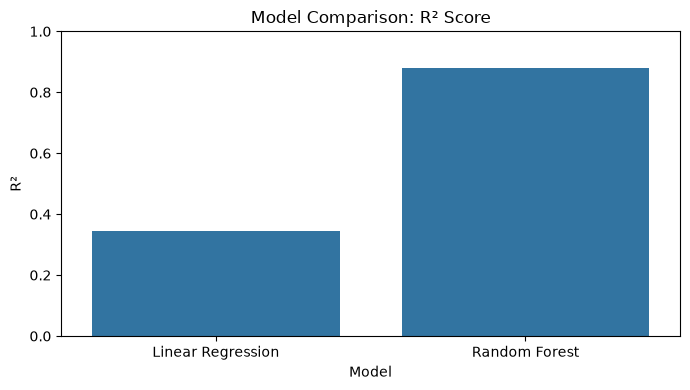

In [12]:
# Compare both models in one table.
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE (₹)": [linear_mae, rf_mae],
    "RMSE (₹)": [linear_rmse, rf_rmse],
    "R²": [linear_r2, rf_r2]
})
display(model_comparison)

# Bar chart for R² comparison.
plt.figure(figsize=(7, 4))
sns.barplot(data=model_comparison, x="Model", y="R²")
plt.title("Model Comparison: R² Score")
plt.ylim(min(0, model_comparison["R²"].min() - 0.05), 1)
plt.tight_layout()
plt.show()

## 10. Visualize Actual vs Predicted Prices

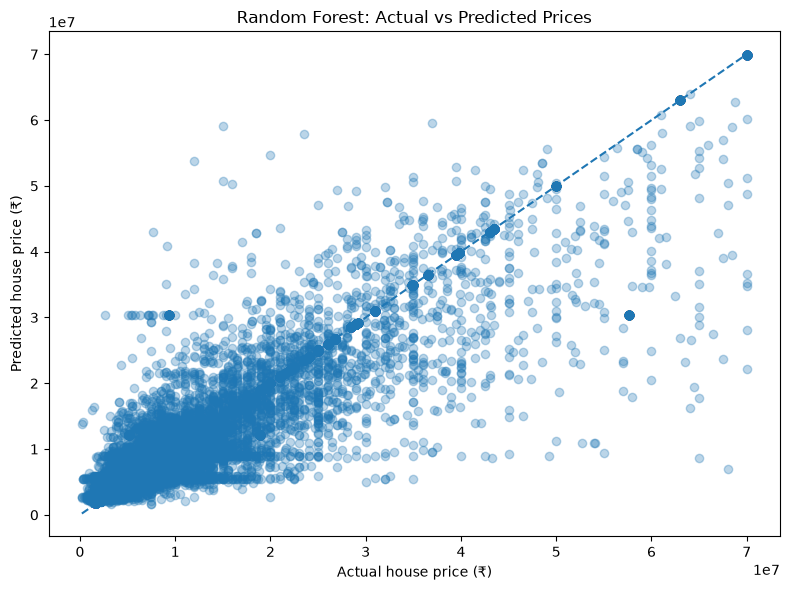

In [13]:
# Scatter plot: one point per test property.
plt.figure(figsize=(8, 6))
plt.scatter(y_test, rf_pred, alpha=0.30)

min_price = min(y_test.min(), rf_pred.min())
max_price = max(y_test.max(), rf_pred.max())
plt.plot([min_price, max_price], [min_price, max_price], linestyle="--")

plt.xlabel("Actual house price (₹)")
plt.ylabel("Predicted house price (₹)")
plt.title("Random Forest: Actual vs Predicted Prices")
plt.tight_layout()
plt.show()

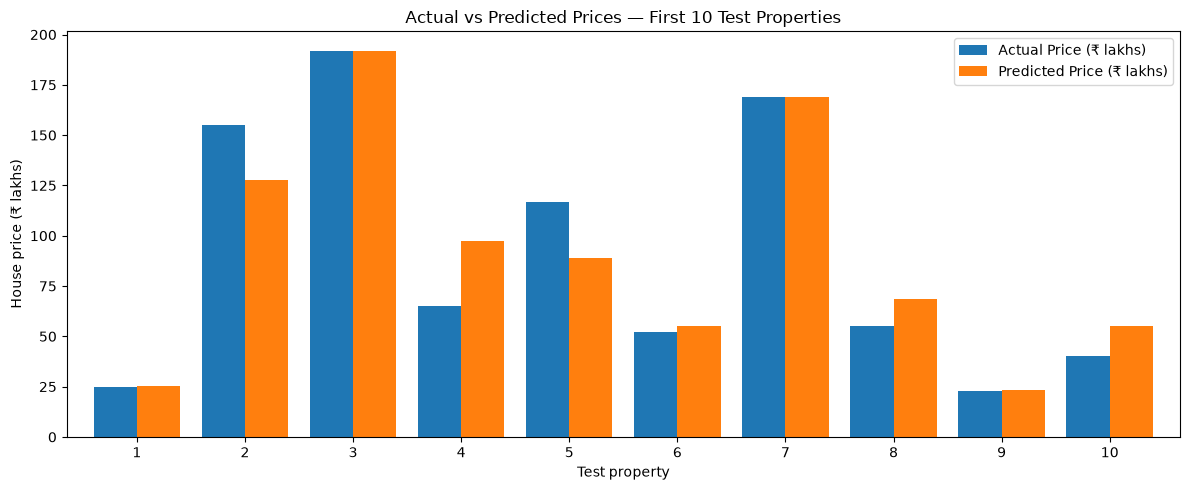

,Actual Price (₹ lakhs),Predicted Price (₹ lakhs)
Test property,,
1,25.0,25.246143
2,155.0,127.759957
3,192.0,192.000000
4,65.0,97.548026
5,117.0,88.854078
6,52.0,55.039142
7,169.0,168.972887
8,55.0,68.618801
9,23.0,23.149997


In [14]:
# Grouped bar chart for only 10 properties, so the plot stays readable.
comparison = pd.DataFrame({
    "Actual Price (₹ lakhs)": y_test.iloc[:10].to_numpy() / 100_000,
    "Predicted Price (₹ lakhs)": rf_pred[:10] / 100_000
}, index=np.arange(1, 11))
comparison.index.name = "Test property"

comparison.plot(kind="bar", figsize=(12, 5), width=0.8)
plt.title("Actual vs Predicted Prices — First 10 Test Properties")
plt.xlabel("Test property")
plt.ylabel("House price (₹ lakhs)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(comparison)

## 11. Predict a Sample Property

In [15]:
sample_house = pd.DataFrame([{
    "location": "thane",
    "Carpet Area (sqft)": 700,
    "Status": "Ready to Move",
    "Floor": "5 out of 20",
    "Transaction": "Resale",
    "Furnishing": "Semi-Furnished",
    "Bathroom": "2",
    "Balcony": "1",
    "Car Parking": "1 Covered"
}])[features]

predicted_price = rf_model.predict(sample_house)[0]

print(f"Predicted house price: ₹{predicted_price:,.2f}")
print(f"Predicted price in lakhs: ₹{predicted_price / 100_000:.2f} lakhs")
print("\\nNote: This is a model estimate, not a verified market valuation.")

Predicted house price: ₹13,602,622.76
Predicted price in lakhs: ₹136.03 lakhs
\nNote: This is a model estimate, not a verified market valuation.


## 12. Save the Trained Model

In [16]:
model_path = "house_price_model.pkl"
joblib.dump(rf_model, model_path)

print("Model saved successfully.")
print("Full path:", os.path.abspath(model_path))
print("File exists:", os.path.exists(model_path))

Model saved successfully.
Full path: c:\Users\pavan\OneDrive\Desktop\practice\house_price_model.pkl
File exists: True


## 13. Conclusion and Limitations

### Conclusion
- A Linear Regression model was trained as a baseline.
- A Random Forest Regressor was trained and compared using MAE, RMSE, and R².
- The Random Forest model performed better on this test split in the original run.

### Limitations
- The baseline experiment excludes properties above the 99th percentile; these listings are not necessarily incorrect.
- The source data contains substantial missingness in some property features.
- Model predictions can be inaccurate, especially for some expensive properties.
- Results apply to this dataset and split and may not generalize to other locations or future listings.
- The sample prediction is an estimate, not a professional property valuation.

### Future Improvements
- Investigate extreme prices and area formats with domain knowledge.
- Extract useful features such as BHK count from `Title`.
- Compare additional models and use cross-validation/hyperparameter tuning.
- Evaluate errors by price range and location.
- Test on a representative external dataset.